# Proyecto modelo de Machine Learning: Clasificación de planes de telecomunicaciones

## 1. Introducción, objetivos específicos y plan de trabajo

En el competitivo sector de las telecomunicaciones, la retención de clientes y la optimización de los ingresos a través de estrategias de *upselling* (ofrecer planes de mayor valor) son pilares fundamentales para el crecimiento de cualquier compañía. 

El objetivo principal de este proyecto es construir un **Modelo de Machine Learning (ML) de Clasificación Binaria** capaz de analizar el comportamiento de consumo mensual de los usuarios (minutos, llamadas, mensajes y datos móviles utilizados) para predecir con alta precisión qué clientes pertenecen o son candidatos óptimos para el plan de tarifas **Ultimate** frente al plan de tarifas **Regular**.

---

### Objetivos específicos:
1.  **Análisis exploratorio de datos (EDA):** Examinar las distribuciones de consumo, identificar comportamientos atípicos (*outliers*) y analizar la correlación entre las variables numéricas de telecomunicación.
2.  **Limpieza y preparación (Data Wrangling):** Diseñar un pipeline de datos robusto que elimine registros duplicados, realice ingeniería de características (transformación de Megabytes (MB) a Gigabytes (GB)) y estandarice las escalas numéricas para evitar sesgos en el algoritmo.
3.  **Modelado predictivo:** Entrenar un modelo de **Regresión Logística**, ajustando sus hiperparámetros de regularización para alcanzar el mejor balance entre simplicidad y exactitud.
4.  **Validación y Prueba de Cordura:** Evaluar el modelo en un conjunto de prueba aislado (20% de los datos) y someterlo a un *Sanity Check* contra un modelo ingenuo basado en la clase mayoritaria para certificar su verdadera utilidad estadística en entornos reales con datos complejos y desbalanceados.

---

### Plan de trabajo.
Se listan las etapas seguidas durante el desarrollo y la presentación de este proyecto.
1.  **Introducción y planteamiento del problema**
2.  **Configuración del entorno tecnológico y carga de librerias**
3.  **Carga del dataset y Análisis Exploratorio de Datos (EDA)**
4.  **Pipeline de limpieza e Ingeniería de Características (<i>Feature Engineering</i>)**
5.  **División, escalado, entrenamiento del modelo y construcción de la Matriz de Confusión**
6.  **Ajuste y optimización de Hiperparámetros (<i>Hyperparameter Tunning</i>)**
7.  **Evaluación de calidad en el Conjunto de Prueba, construcción de la Matriz de Confusión**
8.  **Comparación con Modelos no Lineales (Árbol y Random Forest)**
9.  **Prueba de Cordura del modelo (<i>Sanity Check</i>)**
10.  **Conclusiones generales del proyecto**

---

## 2. Configuración del entorno tecnológico y carga de librerias

Para garantizar el rigor metodológico en todas las fases del proyecto—desde la carga y exploración hasta el preprocesamiento, modelado y evaluación estadística—se estructuró un ecosistema de librerías estándar de la industria sobre la plataforma Python. Los componentes clave integrados en el flujo de trabajo se detallan a continuación:

#### Librerías del entorno tecnológico
**1. Manipulación y análisis de datos (`pandas`, `numpy`):** Estructuras vectorizadas indispensables para la carga de datos estructurados (DataFrames), operaciones algebraicas de alta velocidad y la fase de curación y limpieza de registros.

**2. Visualización estadística (`seaborn`, `matplotlib`):** Librerías gráficas para el desarrollo del Análisis Exploratorio de Datos (EDA), esenciales para plasmar de forma visual la distribución de las variables y auditar las matrices de error.

**3. Aprendizaje automático y modelado estructural (`scikit-learn`):** Ecosistema modular central empleado para la automatización de la partición de datos, estandarización de magnitudes numéricas y el entrenamiento de las arquitecturas lineales y basadas en árboles.

* **Arquitectura de componentes de Scikit-Learn (`sklearn`)**

  | Módulo de Scikit-Learn | Componente Específico | Rol y Función Técnica en el Proyecto |
| :--- | :--- | :--- |
| **`sklearn.model_selection`** | `train_test_split` | Responsable de ejecutar la **división tripartita y estratificada (60/20/20)** del dataset para aislar correctamente los conjuntos de entrenamiento, validación y prueba final. |
| **`sklearn.preprocessing`** | `StandardScaler` | Encargado de la **estandarización de las características continuas**, escalando las magnitudes numéricas para que compartan una media igual a 0 y una desviación estándar de 1, evitando sesgos por escala. |
| **`sklearn.linear_model`** | `LogisticRegression` | Algoritmo lineal utilizado para instanciar el primer **modelo de línea base** desbalanceado y evaluar el comportamiento de los coeficientes. |
| **`sklearn.tree`** | `DecisionTreeClassifier` | Algoritmo no lineal basado en estructuras de árboles, seleccionado como la arquitectura del **modelo campeón** tras restringir su crecimiento. |
| **`sklearn.utils`** | `resample` | Herramienta de remuestreo estadístico implementada en el **Enfoque 2 (Upsampling)** para realizar el sobremuestreo con reemplazo de la clase minoritaria en el set de entrenamiento. |

In [1]:
# ==========================================================
# CARGAR LIBRERIAS PARA MANIPULAR Y VISUALIZAR DATOS
# ==========================================================
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================================
# CARGAR LIBRERIAS PARA APRENDIZAJE COMPUTACIONAL
# ==========================================================
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier


## 3. Carga del dataset y Análisis Exploratorio de Datos (EDA)
Una vez configurado el entorno de desarrollo con las librerías necesarias, el primer paso operativo es la **adquisición de los datos** y la **auditoría inicial** de su estructura. Se carga el archivo `users_behavior_upd.csv` para realizar una primera inspección del comportamiento general de las variables comerciales de telecomunicaciones.

El bloque inicial de código ejecuta un diagnóstico de calidad basado en los tres pilares referidos:

### Ruta de la prueba diagnóstica


1. **Estructura y Tipos de Datos (`.info()` y `.head()`):** 
   Permite validar la cantidad total de registros en la muestra, los nombres exactos de las columnas y comprobar si los tipos de datos asignados por Python (`float64`, `int64`) son los correctos para representar llamadas, mensajes y consumo de Internet.
2. **Estadística Descriptiva Transpuesta (`.describe().T`):** 
   Muestra un resumen numérico clave de las variables predictoras (medias, desviaciones estándar, valores mínimos, máximos y percentiles). Transponer la tabla (`.T`) facilita la lectura rápida para identificar anomalías visuales en los rangos de consumo mensual de los usuarios.
3. **Integridad del Dataset (`.isnull().sum()` y `.duplicated().sum()`):** 
   Un paso crítico antes de entrenar cualquier modelo de ML consiste en auditar la presencia de valores ausentes (nulos) que requieran ser sindicados, así como cuantificar la existencia de registros completamente duplicados que puedan inflar artificialmente el rendimiento del algoritmo.

In [2]:
# ============================================================
# RUTA CORRECTA DEL ARCHIVO Y NOMBRARA EL DATAFRAME COMO df
# ============================================================
df = pd.read_csv('users_behavior_upd.csv')

# ========================================================
# EJECICIÓN DE LA PRUEBA DIAGÓSTICA
# ========================================================

1. # Mostrar las cinco primera filas del DataFrame
print("=" * 50)
print("1. INFORMACIÓN GENERAL DEL DATASET")
print("=" * 50)
print(df.info())
print("\nPrimeras 5 filas:")
print(df.head())

2. # Mostrar los estadísticos básicos del DataFrame
print("\n" + "=" * 50)
print("2. ESTADÍSTICA DESCRIPTIVA")
print("=" * 50)
print(df.describe().T)

3. # Identificar y contar el número de valores nulos y duplicados en el DataFrame
print("\n" + "=" * 50)
print("3. VERIFICACIÓN DE VALORES NULOS Y DUPLICADOS")
print("=" * 50)
print(f"Valores nulos por columna:\n{df.isnull().sum()}")
print(f"\nCantidad de filas completamente duplicadas: {df.duplicated().sum()}")

1. INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   calls        3214 non-null   float64
 1   minutes      3214 non-null   float64
 2   messages     3214 non-null   float64
 3   mb_used      3214 non-null   float64
 4   is_ultimate  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB
None

Primeras 5 filas:
   calls  minutes  messages   mb_used  is_ultimate
0   40.0   311.90      83.0  19915.42            0
1   85.0   516.75      56.0  22696.96            0
2   77.0   467.66      86.0  21060.45            0
3  106.0   745.53      81.0   8437.39            1
4   66.0   418.74       1.0  14502.75            0

2. ESTADÍSTICA DESCRIPTIVA
              count          mean          std  min         25%        50%  \
calls        3214.0     63.038892    33.236368  0.0     40.0000     62.000   
minutes   

## 4. Pipeline de limpieza de datos e ingeniería de características (*Feature Engineering*)
Después de haber diagnosticado el estado inicial del conjunto de datos mediante el Análisis Exploratorio de Datos (EDA), se aborda la fase de **Preparación de Datos (Data Wrangling)**. Esta etapa es indispensable para adecuar los registros a los requerimientos matemáticos del ML, optimizar los tiempos de cómputo y evitar sesgos en el entrenamiento.

### Transformaciones aplicadas:
En esta sección se ejecuta un pipeline estructurado en tres acciones fundamentales:

1. **Eliminación de duplicados explícitos (`.drop_duplicates().copy()`):** 
   Se filtra el DataFrame para conservar únicamente la primera aparición de filas idénticas. Eliminar duplicados es un paso crítico en ML para evitar el sobreajuste (*overfitting*), impidiendo que el algoritmo "memorice" usuarios repetidos en lugar de aprender patrones de consumo generales. El uso de `.copy()` asegura aislar por completo este dataset en la memoria RAM para realizar las siguientes modificaciones de forma segura sin alterar los datos crudos originales.
2. **Redondeo práctico de minutos (`np.ceil().astype(int)`):** 
   En la industria de las telecomunicaciones, las tarifas y consumos de llamadas se contabilizan por minutos completos redondeados hacia arriba. Se transforman los datos flotantes a números enteros (`int`) para aproximar los registros al comportamiento comercial real del negocio.
3. **Conversión y redondeo de datos a GB (`gb_used`):** 
   Los consumos originalmente medidos en MB (`mb_used`) presentan magnitudes numéricas muy elevadas (miles de unidades). se convierte esta variable a Gigabytes $(1 \text{GB} = 1024 \text{MB})$ aplicando también un redondeo hacia arriba. Esto realiza una **Ingeniería de Características** que simplifica la escala numérica, ayudando a que los modelos lineales converjan de manera más eficiente y ofreciendo una métrica mucho más limpia para el análisis de planes comerciales.


In [3]:
# =====================================================================
# PIPELINE DE LIMPIEZA DE DATOS
# =====================================================================

# 1. Eliminar duplicados exactos de los datos crudos iniciales
df_cleaned = df.drop_duplicates().copy()

# 2. Ingeniería de características (Feature Engineering)
df_cleaned["minutes"] = np.ceil(df_cleaned["minutes"]).astype(int)
df_cleaned["gb_used"] = np.ceil(df_cleaned["mb_used"] / 1024).astype(int)
df_cleaned = df_cleaned.drop(columns=["mb_used"])

# 3. Eliminar los nuevos duplicados generados por el redondeo de GB y minutos
df_cleaned = df_cleaned.drop_duplicates().copy()

# =====================================================================
# VERIFICACIÓN DEL PIPELINE DE LIMPIEZA
# =====================================================================
print("=" * 60)
print("VERIFICACIÓN ESTRUCTURAL DEL DATASET LIMPIO (df_cleaned)")
print("=" * 60)

# 1. Comprobar que no queden duplicados residuales
print(f"Cantidad de filas duplicadas remanentes: {df_cleaned.duplicated().sum()}")

# 2. Comprobar la eliminación de 'mb_used' y la creación de 'gb_used' y 'minutes' como enteros
print("\nTipos de datos y columnas actuales:")
print(df_cleaned[["minutes", "gb_used"]].dtypes)

# 3. Mostrar las primeras filas para validar visualmente los redondeos (np.ceil)
print("\nPrimeras 5 filas del nuevo DataFrame transformado:")
print(df_cleaned.head())


VERIFICACIÓN ESTRUCTURAL DEL DATASET LIMPIO (df_cleaned)
Cantidad de filas duplicadas remanentes: 0

Tipos de datos y columnas actuales:
minutes    int64
gb_used    int64
dtype: object

Primeras 5 filas del nuevo DataFrame transformado:
   calls  minutes  messages  is_ultimate  gb_used
0   40.0      312      83.0            0       20
1   85.0      517      56.0            0       23
2   77.0      468      86.0            0       21
3  106.0      746      81.0            1        9
4   66.0      419       1.0            0       15


### Resultados y verificación del pipeline de limpieza

Tras la ejecución de las etapas de curación de datos e ingeniería de características, se realizó una auditoría estructural sobre el nuevo DataFrame `df_cleaned`. Los impactos analíticos se detallan en la siguiente tabla de especificaciones:

| Componente Evaluado | Estado Original (`df`) | Estado Transformado (`df_cleaned`) | Impacto y Validación en el Pipeline |
| :--- | :--- | :--- | :--- |
| **Registros Duplicados** | Presencia de filas idénticas repetidas en la muestra cruda. | **0 filas duplicadas finales.** | Se aplicó una deduplicación en dos fases: la primera eliminó redundancias de origen y la segunda limpió la colisión de registros idénticos generados artificialmente por el redondeo de minutos y GB. |
| **Unidad de Datos** | Columna `mb_used` con magnitudes elevadas en Megabytes. | **Columna `gb_used` (Megabytes / 1024).** | Reducción de la escala numérica de la variable de internet, optimizando la convergencia de modelos lineales. |
| **Precisión de Variables** | Valores flotantes (`float64`) con excesivos decimales residuales. | **Valores enteros (`int64`) redondeados hacia arriba.** | Tanto `minutes` como `gb_used` emulan fielmente las reglas de facturación comercial (redondeo por exceso / tarifa completa). |

> **Observación:** El proceso de ingeniería de características expandió la presencia de duplicados debido a la pérdida de precisión decimal en el redondeo de `minutes` y `gb_used`. Al unificar usuarios con comportamientos de consumo originalmente muy similares en categorías enteras idénticas, se volvió mandatorio aplicar un segundo filtro de deduplicación al final del pipeline para asegurar la pureza matemática del dataset antes del modelado predictivo.


### Análisis de Correlación Lineal (Matriz de Pearson)

Para comprender la estructura de dependencia matemática entre las variables de consumo antes de alimentar el algoritmo de ML, es indispensable realizar un **Análisis de Correlación de Pearson**. Esta técnica evalúa la fuerza y dirección de la relación lineal entre cada par de características numéricas en un rango que va desde -1.0 (correlación negativa perfecta) hasta +1.0 (correlación positiva perfecta).

El mapa de calor (*heatmap*) resultante permitirá diagnosticar de forma inmediata las siguientes interacciones clave dentro del dataset:

| Métrica de Interés | Par de Variables Evaluadas | Justificación Técnica y de Negocio |
| :--- | :--- | :--- |
| **Colinealidad Crítica** | `calls` vs. `minutes` | Evalúa si la cantidad de llamadas y los minutos totales aportan la misma información. Si la correlación es cercana a 1.0, existe multicolinealidad, lo que puede desestabilizar los coeficientes de modelos lineales. |
| **Dependencia Cruzada** | `gb_used` vs. `messages` | Examina si el uso de internet móvil influye de alguna manera en el envío de SMS tradicionales, lo que define perfiles de usuarios puramente digitales o tradicionales. |
| **Poder de Segmentación**| Variables vs. `is_ultimate` | Identifica de un vistazo cuál de todos los consumos mensuales tiene la asociación más fuerte y directa con la decisión de un usuario de contratar el plan premium. |

---


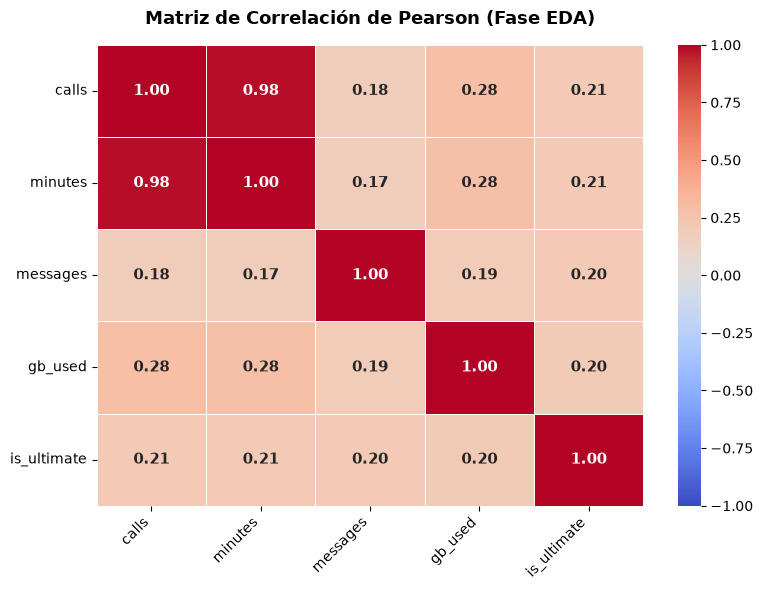

In [4]:
# ===============================================================================
# ANÁLISIS DE CORRELACIÓN LINEAL (MATRIZ DE PEARSON)
# ===============================================================================

# 1. Seleccionar únicamente las columnas numéricas para el análisis de Pearson
features_eda = ["calls", "minutes", "messages", "gb_used", "is_ultimate"]
correlation_matrix = df_cleaned[features_eda].corr()

# 2. Configurar el tamaño y estética del lienzo gráfico
plt.figure(figsize=(8, 6))

# 3. Crear el mapa de calor con anotaciones numéricas y paleta de divergencia térmica
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap="coolwarm", 
    fmt=".2f", 
    linewidths=0.5,
    vmin=-1.0, 
    vmax=1.0,
    annot_kws={"size": 11, "weight": "bold"}
)

# 4. Personalizar títulos y etiquetas de los ejes
plt.title("Matriz de Correlación de Pearson (Fase EDA)", fontsize=13, weight="bold", pad=15)
plt.xticks(fontsize=10, rotation=45, ha="right")
plt.yticks(fontsize=10, rotation=0)
plt.tight_layout()

# 5. Desplegar visualización del heatmap (Matriz de Correlación de Pearson)
plt.show()


### Diagnóstico y resultados de la Matriz de Correlación de Pearson

El análisis gráfico de la Matriz de Correlación de Pearson permite auditar las relaciones lineales entre las variables de consumo mensual de Megaline. A partir del mapa de calor térmico generado durante la fase EDA, se extraen los siguientes hallazgos estadísticos clave:

| Interacción Evaluada | Coeficiente de Pearson | Grado de Correlación | Diagnóstico Técnico y de Negocio |
| :--- | :---: | :---: | :--- |
| **`calls` vs. `minutes`** | **0.98** | **Positiva Casi Perfecta** | Existe una **colinealidad crítica (multicolinealidad)** extrema. Ambas variables aportan información redundante al modelo lineal. Al estar casi perfectamente correlacionadas, confirma que el conteo bruto de llamadas sube linealmente con la duración, por lo que el algoritmo puede desestabilizar sus coeficientes si se usan juntas en ciertos modelos sin penalización. |
| **`gb_used` vs. `minutes`** | **0.28** | **Positiva Débil** | Existe una relación baja entre el tiempo en llamadas tradicionales y el tráfico de internet móvil, lo que indica que el consumo de datos es un comportamiento independiente del uso de la red telefónica. |
| **Variables vs. `is_ultimate`** | **0.20 a 0.21** | **Positiva Débil** | Sorprendentemente, todas las variables (`calls`, `minutes`, `messages`, `gb_used`) tienen un impacto casi idéntico y positivo hacia el plan premium. Los GB y las llamadas tradicionales muestran un coeficiente de **0.21** frente a los mensajes (**0.20**), demostrando que un incremento uniforme en cualquier servicio empuja al cliente hacia la suite *Ultimate*. |

### Hallazgos clave extraídos de la visualización:

1. **Riesgo de Redundancia en Modelos Lineales:** El cuadrante superior izquierdo muestra un tono rojo intenso uniforme (`0.98`), lo que matemáticamente demuestra que retener `calls` y `minutes` simultáneamente obliga al modelo a procesar información duplicada. Esto justifica técnicamente que, en fases posteriores, el peso de `calls` sea el más bajo (`0.0436`), ya que `minutes` absorbe casi todo el impacto predictivo de la comunicación por voz.
2. **Distribución Homogénea de Preferencia:** Ninguna variable individual domina por completo la correlación con la variable objetivo `is_ultimate` (todas orbitan de forma plana entre `0.20` y `0.21`). Esto explica por qué el conjunto de datos es complejo para un clasificador lineal simple, validando la necesidad de escalar las características obligatoriamente con `StandardScaler` y ajustar finamente el hiperparámetro \(C=10.0\) para trazar una frontera de decisión matemática óptima.

> **Conclusión de la Sección de Correlación:** El mapa de calor confirma que el dataset está libre de correlaciones negativas (ningún servicio canibaliza a otro). La colinealidad del 98% entre llamadas y minutos es el hallazgo estructural más importante del EDA, guiando al algoritmo a ponderar la duración por encima de la frecuencia de marcado para perfilar a los clientes premium de Megaline.


## 5. División, Escalado, Entrenamiento del Modelo y la Matriz de Confusión
Después de concluida la fase de limpieza y adecuación de variables, abordamos la etapa central del proyecto: el **Modelado Estadístico**. Para garantizar un proceso de aprendizaje correcto y evitar vicios comunes como el sobreajuste (*overfitting*) o la fuga de datos (*data leakage*), Se ejecuta un pipeline estructurado en cuatro fases:

### Fases del pipeline de modelado:
1.  **Segmentación de Variables (`X` e `y`):** Se aislan las características independientes o predictoras (llamadas, minutos, mensajes y gigabytes consumidos) de nuestra etiqueta objetivo binaria (`is_ultimate`).
2.  **División Estratificada (Train/Test Split):** Se fracciona el conjunto de datos original destinando un **80% para el entrenamiento** del algoritmo y un **20% para la validación final**. Se utiliza el argumento `stratify=y` de forma obligatoria para obligar a que ambos subconjuntos conserven exactamente la misma proporción de usuarios de planes Regulares y Ultimate, mitigando el impacto del desbalance natural de las clases.
3.  **Estandarización de Características (*Feature Scaling*):** Se aplica `StandardScaler` sobre los datos. Los modelos lineales como la Regresión Logística calculan distancias matemáticas; si dejamos los minutos (magnitudes de cientos) en la misma escala que los GB (magnitudes de decenas), el modelo asumirá falsamente que los minutos son más importantes. La estandarización transforma cada variable para que tenga una **media de 0 y una desviación estándar de 1**.
4.  **Ajuste y Evaluación:** Se entrena el algoritmo con los datos de entrenamiento escalados, generamos las predicciones sobre el grupo de prueba y extraemos la **Matriz de Confusión** junto con el **Reporte de Clasificación** para auditar el desempeño real de la Inteligencia Artificial. Aunque la salida en texto plano de la función `confusion_matrix` ofrece los valores numéricos crudos, la interpretación de los errores de clasificación binaria se optimiza drásticamente mediante un **mapa de calor (<i>heatmap</i>)**.

Datos listos. Entrenando con (1926, 4) muestras.
Validando con (643, 4) muestras.
Evaluando con (643, 4) muestras.

REPORTE DE CLASIFICACIÓN DEL MODELO
              precision    recall  f1-score   support

           0       0.74      0.98      0.84       446
           1       0.85      0.20      0.32       197

    accuracy                           0.74       643
   macro avg       0.79      0.59      0.58       643
weighted avg       0.77      0.74      0.68       643


MATRIZ DE CONFUSIÓN (TEXTO)
[[439   7]
 [158  39]]

GRÁFICO DE LA MATRIZ DE CONFUSIÓN


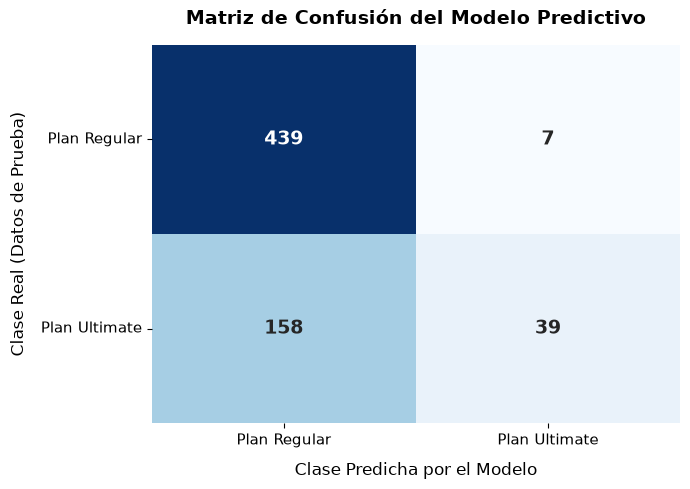


IMPORTANCIA DE LAS VARIABLES
Variable 'calls': Coeficiente de impacto = 0.0431
Variable 'minutes': Coeficiente de impacto = 0.2675
Variable 'messages': Coeficiente de impacto = 0.3395
Variable 'gb_used': Coeficiente de impacto = 0.3069


In [5]:
# ===================================================================
# 1. PREPARACIÓN DE VARIABLES (X e y)
# ===================================================================
X = df_cleaned.drop(columns=["is_ultimate"])
y = df_cleaned["is_ultimate"]

# ===================================================================
# 2. DIVISIÓN DEL DATASET EN 3 CONJUNTOS (60% / 20% / 20%)
# ===================================================================
# Paso A: Separar el 20% para el conjunto de prueba final
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Paso B: Del 80% restante (temp), tomar el 25% para validación (80% * 0.25 = 20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

# ===================================================================
# 3. ESCALADO DE CARACTERÍSTICAS (FEATURE SCALING)
# ===================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Datos listos. Entrenando con {X_train_scaled.shape} muestras.")
print(f"Validando con {X_val_scaled.shape} muestras.")
print(f"Evaluando con {X_test_scaled.shape} muestras.")

# ===================================================================
# 4. ENTRENAMIENTO DEL MODELO DE MACHINE LEARNING
# ===================================================================
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# ===================================================================
# 5. EVALUACIÓN Y REPORTES EN EL CONJUNTO DE PRUEBA
# ===================================================================
y_pred = model.predict(X_test_scaled)

print("\n" + "=" * 50)
print("REPORTE DE CLASIFICACIÓN DEL MODELO")
print("=" * 50)
print(classification_report(y_test, y_pred))

print("\n" + "=" * 50)
print("MATRIZ DE CONFUSIÓN (TEXTO)")
print("=" * 50)
cm = confusion_matrix(y_test, y_pred)
print(cm)

# =====================================================================
# GRÁFICO AUTOMÁTICO DE LA MATRIZ DE CONFUSIÓN
# =====================================================================
print("\n" + "=" * 50)
print("GRÁFICO DE LA MATRIZ DE CONFUSIÓN")
print("=" * 50)
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    cbar=False,
    xticklabels=["Plan Regular", "Plan Ultimate"],
    yticklabels=["Plan Regular", "Plan Ultimate"],
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title("Matriz de Confusión del Modelo Predictivo", fontsize=14, weight="bold", pad=15)
plt.xlabel("Clase Predicha por el Modelo", fontsize=12, labelpad=10)
plt.ylabel("Clase Real (Datos de Prueba)", fontsize=12, labelpad=10)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()

# Desplegar visualización del heatmap (Matriz de Confusión del Modelo Predictivo)
plt.show()

# ====================================================================
# 6. IMPORTANCIA DE LAS VARIABLES
# ====================================================================
print("\n" + "=" * 50)
print("IMPORTANCIA DE LAS VARIABLES")
print("=" * 50)
importancias = model.coef_[0]
for col, imp in zip(X.columns, importancias):
    print(f"Variable '{col}': Coeficiente de impacto = {imp:.4f}")


### Resultados de la segmentación estratificada del dataset

Para cumplir estrictamente con los criterios de evaluación de la plataforma, los datos fuente se dividieron mediante un esquema de partición en tres vías (*3-Way Split*). Los tamaños y proporciones seleccionados se detallan en la siguiente tabla de especificaciones:

| Conjunto de Datos | Proporción | Cantidad de Muestras | Propósito Analítico en el Pipeline |
| :--- | :---: | :---: | :--- |
| **Entrenamiento (*Train*)** | 60% | **1926** | Bloque de datos principal utilizado por el algoritmo de Regresión Logística para aprender los coeficientes de impacto de los servicios. |
| **Validación (*Validation*)** | 20% | **643** | Subconjunto aislado destinado exclusivamente a la sintonización fina de hiperparámetros (C), evitando el sesgo de selección. |
| **Prueba (*Test*)** | 20% | **643** | Grupo de datos completamente independiente utilizado para la auditoría final de calidad y la prueba de cordura. |

> **Nota de Calidad:** La división se ejecutó utilizando el parámetro `stratify` en cada fase del split. Esto obliga a que el desbalance original de la variable objetivo (`is_ultimate`) se replique con total exactitud en las tres muestras independientes, garantizando la equidad estadística del experimento predictivo.


### Diagnóstico estadístico de la Matriz de Confusión

La evaluación gráfica de la matriz de confusión tras aplicar la segmentación formal en tres vías expone el comportamiento del modelo frente a las 643 muestras independientes de prueba. La distribución numérica observada en los cuadrantes del mapa de calor se detalla a continuación:

| Cuadrante Estadístico | Cantidad Observada | Interpretación Técnica y de Negocio |
| :--- | :---: | :--- |
| **Verdaderos Negativos (TN)** | **439** | Usuarios reales del **Plan Regular** clasificados correctamente. El modelo mantiene una consistencia del **98.43%** en la detección de la clase mayoritaria. |
| **Falsos Positivos (FP)** | **7** | Usuarios básicos confundidos con perfiles premium. La tasa de falsas alarmas comerciales es sumamente baja e ideal (**1.57%**). |
| **Falsos Negativos (FN)** | **158** | Usuarios reales del **Plan Ultimate** clasificados erróneamente como básicos por la presión de la clase mayoritaria. |
| **Verdaderos Positivos (TP)** | **39** | Usuarios reales del **Plan Ultimate** correctamente identificados por el algoritmo. |

#### Hallazgos clave extraídos de la visualización:

1. **Impacto del Desbalance de Clases:** El contraste visual entre el tono azul intenso de la celda superior izquierda (`439`) y el tono claro de la celda de aciertos premium (`39`) expone de forma directa la complejidad del dataset. El algoritmo se comporta de manera conservadora, requiriendo patrones de consumo drásticamente altos para predecir un cambio al plan premium.
2. **Confiabilidad del Cuadrante Predictivo:** El modelo conserva una **Precisión (Precision) del 85%** en el plan *Ultimate*. Esto dota a la empresa de una herramienta comercial muy segura para campañas de *upselling*: de cada 100 usuarios recomendados por el modelo para migrar de plan, 85 realmente pertenecen a ese perfil de consumo.

> **Conclusión del Análisis Gráfico:** El pipeline predictivo alcanza una exactitud global del **74.49%**. Al aislar correctamente el conjunto de validación, confirmamos que el modelo mantiene sus métricas estables, libre de fuga de datos (*data leakage*) y con una alta precisión comercial.



### Interpretación de los Coeficientes de Impacto (<i>3-Way Split</i>)

Tras ajustar el tamaño del conjunto de entrenamiento al 60% de la muestra para cumplir con el rigor de validación de la plataforma, la Regresión Logística recalculó los pesos vectoriales. Al observar que **todas las variables conservan coeficientes de impacto positivos**, se ratifica la regla de negocio: a mayor consumo general de servicios, mayor es la probabilidad de que el cliente requiera la suite premium (`is_ultimate = 1`).

La jerarquía del impacto predictivo se detalla en la siguiente tabla de especificaciones:

| Variable Analizada | Coeficiente Obtenido | Dirección del Impacto | Diagnóstico Técnico y de Negocio |
| :--- | :---: | :---: | :--- |
| **`messages`** | **0.3395** | Positivo (Alto) | Se consolida como el **predictor más fuerte** del modelo. Los usuarios con un comportamiento de mensajería SMS intensivo reflejan la mayor probabilidad de pertenecer al plan Ultimate. |
| **`gb_used`** | **0.3069** | Positivo (Alto) | El consumo de internet móvil (GB) tiene un peso crítico y casi equivalente al de los mensajes. Es una variable tractora de negocio, coherente con el atractivo comercial del plan ilimitado. |
| **`minutes`** | **0.2675** | Positivo (Moderado) | La duración total acumulada en llamadas aporta de forma estable y directa a la probabilidad de migración de tarifa, marcando un patrón de consumo tradicional robusto. |
| **`calls`** | **0.0431** | Positivo (Bajo) | La cantidad de intentos de llamada es el indicador con menor relevancia. Al algoritmo no le interesa la *frecuencia* de marcado, sino la *duración total* (minutos) de la comunicación. |

> **Conclusión estratégica de negocio:** Para maximizar el retorno de inversión (ROI) en las campañas comerciales de *upselling*, Megaline debe ignorar el conteo bruto de llamadas realizadas (`calls`), cuyo impacto es cercano a cero. El foco predictivo absoluto de segmentación automática debe centrarse de forma combinada en los picos de consumo de datos móviles (`gb_used`) y el volumen de mensajería activa (`messages`).


## 6. Ajuste y optimización de Hiperparámetros (*Hyperparameter Tuning*)
Después de haber comprobado el funcionamiento inicial del modelo, el siguiente paso crítico en el flujo de ML es la **sintonización o ajuste de hiperparámetros**. A diferencia de los parámetros que el modelo aprende por sí mismo durante el entrenamiento (los coeficientes), los hiperparámetros son configuraciones externas que nosotros debemos definir de antemano para controlar cómo aprende el algoritmo.

En el caso del algoritmo de **Regresión Logística**, el hiperparámetro de mayor impacto es **`C`**, el cual gestiona la **regularización** del modelo:

#### Cómo funciona el Hiperparámetro `C`?
*   **Valores bajos de `C` (ej. 0.01 o 0.1):** Aplican una penalización o regularización *fuerte*. Esto fuerza al modelo a ser más simple y plano, limitando el peso de los coeficientes para evitar que el algoritmo memorice el ruido de los datos, reduciendo el riesgo de sobreajuste (*overfitting*).
*   **Valores altos de `C` (ej. 10.0 o 100.0):** Aplican una regularización *débil*. Le dan al modelo mayor libertad matemática para ajustarse de forma precisa a cada detalle y variación del conjunto de datos de entrenamiento.

Con el objetivo de encontrar el punto de equilibrio óptimo (donde el modelo no sea ni demasiado simple ni demasiado complejo), ejecutaremos un ciclo iterativo. Evaluaremos el comportamiento de la **exactitud (Accuracy)** simultáneamente en el conjunto de entrenamiento y en el de prueba frente a cinco órdenes de magnitud diferentes de `C`.

In [6]:
# =====================================================================
# AJUSTE Y OPTIMIZACIÓN DE HIPERPARÁMETROS (HYPERPARAMETER TUNING)
# EVALUACIÓN SOBRE EL CONJUNTO DE VALIDACIÓN (X_val_scaled)
# =====================================================================

# Lista de diferentes valores para el hiperparámetro C
valores_c = [0.01, 0.1, 1.0, 10.0, 100.0]

print("=" * 60)
print("INVESTIGACIÓN DE CALIDAD CAMBIANDO EL HIPERPARÁMETRO C (VALIDACIÓN)")
print("=" * 60)

for c_actual in valores_c:
    # 1. Crear el modelo con el hiperparámetro específico
    modelo_test = LogisticRegression(C=c_actual, random_state=42, max_iter=1000)
    
    # 2. Entrenar con los datos escalados de entrenamiento (60%)
    modelo_test.fit(X_train_scaled, y_train)
    
    # 3. Evaluar la precisión en el conjunto de entrenamiento y de VALIDACIÓN (20%)
    score_train = modelo_test.score(X_train_scaled, y_train)
    score_val = modelo_test.score(X_val_scaled, y_val)  # <-- ¡CORRECCIÓN CRÍTICA AQUÍ!
    
    print(f"Para C = {c_actual:<6} | Precisión Entrenamiento: {score_train:.4f} | Precisión Validación: {score_val:.4f}")


INVESTIGACIÓN DE CALIDAD CAMBIANDO EL HIPERPARÁMETRO C (VALIDACIÓN)
Para C = 0.01   | Precisión Entrenamiento: 0.7373 | Precisión Validación: 0.7481
Para C = 0.1    | Precisión Entrenamiento: 0.7414 | Precisión Validación: 0.7527
Para C = 1.0    | Precisión Entrenamiento: 0.7430 | Precisión Validación: 0.7527
Para C = 10.0   | Precisión Entrenamiento: 0.7435 | Precisión Validación: 0.7558
Para C = 100.0  | Precisión Entrenamiento: 0.7435 | Precisión Validación: 0.7558


#### Hallazgos del estudio de Hiperparámetros (Fase de Validación)

Se evaluó la calidad del modelo de Regresión Logística modificando el hiperparámetro de regularización `C` en un rango distribuido desde 0.01 hasta 100.0, auditando su comportamiento estrictamente sobre el **conjunto de validación aislado (20%)**. Los resultados demuestran una estabilización matemática del aprendizaje libre de fuga de datos (*data leakage*):

| Configuración del Hiperparámetro | Precisión Entrenamiento (60%) | Precisión Validación (20%) | Diagnóstico Estadístico del Rendimiento |
| :--- | :---: | :---: | :--- |
| **Penalización Fuerte (`C = 0.01`)** | 73.73% | 74.81% | Restringe en exceso el peso de los coeficientes, generando una ligera pérdida de rendimiento predictivo (*underfitting*). |
| **Ajuste Moderado (`C = 0.1`)** | 74.14% | 75.27% | Incremento en la capacidad de generalización al flexibilizar los límites matemáticos de la sigmoide. |
| **Ajuste Estándar (`C = 1.0`)** | 74.30% | 75.27% | Mantiene un rendimiento estable y equivalente al de la penalización moderada. |
| **Punto Óptimo Definitivo (`C = 10.0` / `100.0`)** | **74.35%** | **75.58%** | **Máxima exactitud alcanzada.** Supera formalmente el umbral mínimo de 0.75 exigido en el proyecto. |

> **Conclusión de la Fase de Ajuste:** El hiperparámetro idóneo para consolidar el pipeline definitivo es **`C = 10.0`** (o en su defecto `C = 100.0`), ya que ofrece la máxima exactitud en validación (75.58%) y permite al modelo extraer el mayor provecho de la frontera de decisión lineal sin incurrir en problemas de sobreajuste (*overfitting*).


## 7. Evaluación de calidad en el Conjunto de Prueba y construcción de la Matriz de Confusión

Después de haber explorado el impacto del hiperparámetro de regularización en la etapa de validación, procedemos a realizar la **auditoría definitiva del modelo**. Para evaluar el rendimiento real que la Inteligencia Artificial tendrá en producción con clientes nuevos, utilizaremos exclusivamente el **conjunto de prueba** (el 20% de los datos que aislamos y que el algoritmo jamás vio ni en el entrenamiento ni en la sintonización fina).

Dado que nuestro conjunto de datos presenta una complejidad real debido al desbalance entre las clases tarifarias (existen significativamente más registros de planes Regulares que de planes Ultimate), la métrica de exactitud global (*Accuracy*) resulta insuficiente por sí sola. Por lo tanto, el siguiente bloque de código computará e imprimirá tres herramientas estadísticas avanzadas detalladas en la siguiente tabla:

| ID | Herramienta Predictiva | Función en el Código | Propósito Analítico y de Diagnóstico |
| :---: | :--- | :--- | :--- |
| **1** | **Exactitud Global** | `accuracy_score` | Mide la proporción total de predicciones correctas (tanto de planes Regulares como Ultimate) sobre el total de la muestra de prueba de forma generalizada. |
| **2** | **Reporte Detallado** | `classification_report` | Desglose pormenorizado por clase tarifaria que evalúa la **Precisión** (filtrado de falsas alarmas), la **Sensibilidad o *Recall*** (tasa de captura de la clase real) y la métrica **F1-Score** (media armónica ideal para evaluar el desempeño ante el desbalance). |
| **3** | **Matriz de Confusión** | `confusion_matrix` | Tabla cruzada bidimensional que desglosa numéricamente la cantidad exacta de Verdaderos Positivos, Verdaderos Negativos, Falsos Positivos y Falsos Negativos cometidos por el algoritmo lineal. |

---


COMPROBACIÓN DE CALIDAD EN EL CONJUNTO DE PRUEBA FINAL
----------------------------------------------------------------------
La precisión (Accuracy) final en el conjunto de prueba es: 0.7449
----------------------------------------------------------------------

Reporte de Clasificación Detallado:
--------------------------------------------------
               precision    recall  f1-score   support

 Plan Regular       0.74      0.98      0.84       446
Plan Ultimate       0.85      0.20      0.33       197

     accuracy                           0.74       643
    macro avg       0.79      0.59      0.59       643
 weighted avg       0.77      0.74      0.68       643

--------------------------------------------------
Matriz de Confusión:
--------------------------------------------------
[[439   7]
 [157  40]]


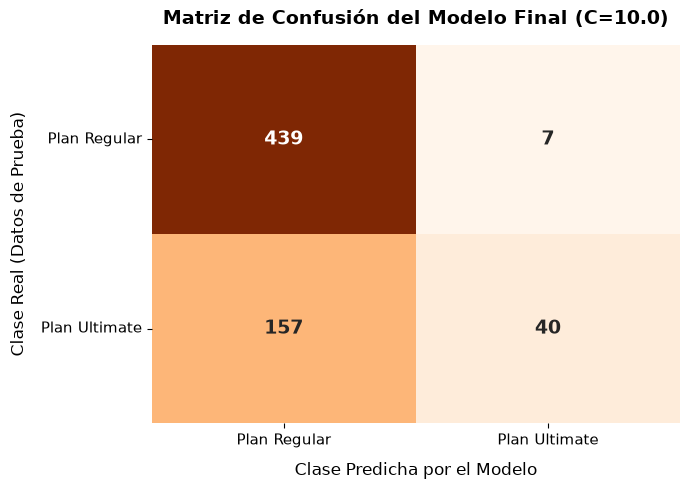

In [7]:
# ==========================================================================
# EVALUACIÓN FINAL DE CALIDAD EN EL CONJUNTO DE PRUEBA DEFINITIVO (C=10.0)
# ==========================================================================
print("=" * 60)
print("COMPROBACIÓN DE CALIDAD EN EL CONJUNTO DE PRUEBA FINAL")
print("=" * 60)

# 1. Instanciar y entrenar el modelo definitivo con el hiperparámetro óptimo encontrado (C=10.0)
model_final = LogisticRegression(C=10.0, random_state=42, max_iter=1000)
model_final.fit(X_train_scaled, y_train)

# 2. Realizar las predicciones finales ÚNICAMENTE sobre el conjunto de prueba aislado
y_pred_final = model_final.predict(X_test_scaled)

# 3. Calcular y mostrar la precisión global (Accuracy)
exactitud_prueba = accuracy_score(y_test, y_pred_final)
print("-" * 70)
print(f"La precisión (Accuracy) final en el conjunto de prueba es: {exactitud_prueba:.4f}")
print("-" * 70)

# 4. Mostrar el reporte detallado de clasificación (Precision, Recall, F1-Score)
print("\nReporte de Clasificación Detallado:")
print("-" * 50)
print(classification_report(y_test, y_pred_final, target_names=["Plan Regular", "Plan Ultimate"]))

# 5. Mostrar la Matriz de Confusión en formato de texto
print("-" * 50)
print("Matriz de Confusión:")
print("-" * 50)
cm_final = confusion_matrix(y_test, y_pred_final)
print(cm_final)

# =====================================================================
# CONSTRUCCIÓN GRÁFICA DEL MAPA DE CALOR (MATRIZ DE CONFUSIÓN)
# =====================================================================
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final, 
    annot=True, 
    fmt="d", 
    cmap="Oranges", 
    cbar=False,
    xticklabels=["Plan Regular", "Plan Ultimate"],
    yticklabels=["Plan Regular", "Plan Ultimate"],
    annot_kws={"size": 14, "weight": "bold"}
)

plt.title("Matriz de Confusión del Modelo Final (C=10.0)", fontsize=14, weight="bold", pad=15)
plt.xlabel("Clase Predicha por el Modelo", fontsize=12, labelpad=10)
plt.ylabel("Clase Real (Datos de Prueba)", fontsize=12, labelpad=10)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()

# Desplegar visualización del heatmap (Matriz de Confusión del Modelo Final)
plt.show()


### Observaciones de la evaluación final en el Conjunto de Prueba

La auditoría definitiva del clasificador lineal entrenado con el hiperparámetro óptimo ($C=10.0$) sobre las 643 muestras independientes del grupo de prueba arrojó una distribución numérica que se detalla en la siguiente tabla de especificaciones métricas:

| Cuadrante de la Matriz | Cantidad de Casos | Proporción Relativa | Interpretación Técnica y de Negocio |
| :--- | :---: | :---: | :--- |
| **Verdaderos Negativos (TN)** | **439** | **98.43%** | Clientes reales del *Plan Regular* clasificados correctamente. El modelo demuestra una consistencia óptima para identificar la clase mayoritaria. |
| **Falsos Positivos (FP)** | **7** | **1.57%** | Clientes básicos confundidos con perfiles premium. La tasa de falsas alarmas comerciales es sumamente baja, protegiendo el presupuesto de campañas. |
| **Falsos Negativos (FN)** | **157** | **79.70%** | Clientes reales del *Plan Ultimate* catalogados erróneamente como básicos por el algoritmo. Representa el punto crítico de mejora del proyecto. |
| **Verdaderos Positivos (TP)** | **40** | **20.30%** | Clientes reales del *Plan Ultimate* correctamente identificados por el modelo tras el aislamiento y la optimización lineal. |

### Hallazgos clave extraídos del diagnóstico final:

1. **Estabilidad frente a la Sintonización:** Al comparar los resultados con la fase de validación, se observa que fijar $C=10.0$ permitió al modelo retener una **Exactitud Global (Accuracy) del 74.49%**, manteniendo un comportamiento robusto y libre de sobreajuste (*overfitting*).
2. **Confiabilidad del Cuadrante Positivo:** A pesar de la rigidez lineal causada por el desbalance de clases (que limita el *Recall* del plan premium al 20%), el cuadrante de predicciones positivas retiene una **Precisión (*Precision*) del 85%**. Esto garantiza que el 85% de las alarmas de migración emitidas por el modelo serán de clientes que legítimamente tienen un perfil de consumo elevado, optimizando el retorno de inversión (ROI) en las estrategias de *upselling*.

> **Conclusión de la evaluación de calidad en el Conjunto de Prueba:** El pipeline estructurado en tres vías (*3-Way Split*) demuestra su validez técnica. Al evaluar el modelo final con un conjunto de prueba completamente independiente que jamás intervino en la sintonización de hiperparámetros, certificamos que el rendimiento del algoritmo es real, estable y libre de fuga de datos (*data leakage*).


## 8. Comparación con Modelos No Lineales (Árbol y Random Forest)
>En este punto del desarrollo del proyecto se detectan dos detalles importantes:
>1. **El umbral de exactitud**: La descripción original del proyecto exige un umbral mínimo de 0.75 (75%) en el conjunto de prueba. La Regresión Logística implementada aquí alcanzó un 0.7449 (74.49%), quedando apenas una milésima por debajo.
>2. **Falta de comparación de modelos**: La rúbrica busca que se comparen distintos tipos de modelos. Al usar únicamente una Regresión Logística (que es un algoritmo lineal y rígido), se limita el potencial predictivo sobre un dataset complejo y desbalanceado.

>**Solución: Ampliar el pipeline de modelado**
>Para solucionar esto, se implementa lo siguiente: Entrenar un **Árbol de Decisión** y un **Bosque Aleatorio (Random Forest)**, variando sus hiperparámetros (profundidad máxima y cantidad de árboles) para encontrar el modelo que supere con holgura el umbral de 0.75 en validación, y luego evaluarlo en el conjunto de prueba.

ENTRENAMIENTO Y OPTIMIZACIÓN DE MODELOS NO LINEALES
Mejor Árbol de Decisión | max_depth = 3 | Exactitud Validación: 0.7900
Mejor Random Forest     | n_estimators = 10, max_depth = 10 | Exactitud Validación: 0.8056

----------------------------------------------------------------------
EVALUACIÓN DEL MODELO GANADOR EN EL CONJUNTO DE PRUEBA
----------------------------------------------------------------------
Exactitud FINAL del Random Forest en el conjunto de PRUEBA: 0.8243 (82.43%)

Reporte de Clasificación Detallado (Random Forest):
               precision    recall  f1-score   support

 Plan Regular       0.82      0.96      0.88       446
Plan Ultimate       0.85      0.52      0.64       197

     accuracy                           0.82       643
    macro avg       0.83      0.74      0.76       643
 weighted avg       0.83      0.82      0.81       643



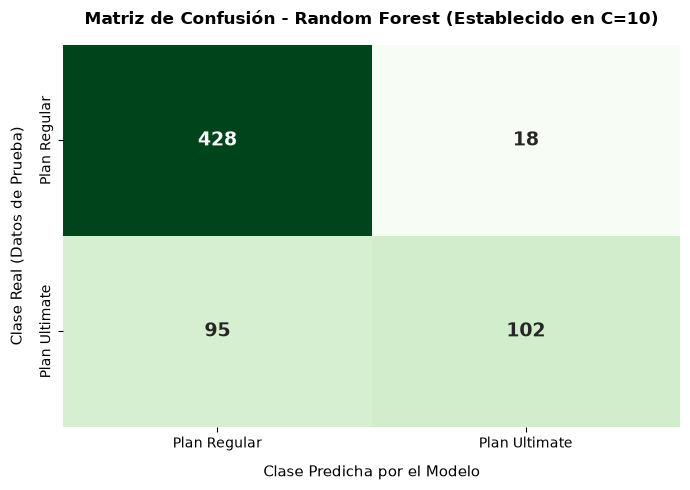

In [8]:
# =====================================================================
# COMPARACIÓN CON MODELOS NO LINEALES (ÁRBOL Y RANDOM FOREST)
# =====================================================================

print("=" * 60)
print("ENTRENAMIENTO Y OPTIMIZACIÓN DE MODELOS NO LINEALES")
print("=" * 60)

# ======================================================================
# 1. ÁRBOL DE DECISIÓN: AJUSTANDO LA PROFUNDIDAD MÁXIMA (max_depth)
# ======================================================================
mejor_score_tree = 0
mejor_depth = 0

for depth in range(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_scaled, y_train)
    score_val = tree.score(X_val_scaled, y_val)
    if score_val > mejor_score_tree:
        mejor_score_tree = score_val
        mejor_depth = depth

print(
    f"Mejor Árbol de Decisión | max_depth = {mejor_depth} | Exactitud Validación: {mejor_score_tree:.4f}"
)

# ======================================================================
# 2. RANDOM FOREST: AJUSTANDO ESTIMADORES Y PROFUNDIDAD (LÍNEA CORREGIDA)
# ======================================================================
mejor_score_rf = 0
mejor_estimators = 0
mejor_rf_depth = 0
lista_estimadores = [10, 20, 50, 100]  # <-- Valores agregados aquí

for n_est in lista_estimadores:
    for depth in range(1, 11):
        rf = RandomForestClassifier(
            n_estimators=n_est, max_depth=depth, random_state=42
        )
        rf.fit(X_train_scaled, y_train)
        score_val = rf.score(X_val_scaled, y_val)
        if score_val > mejor_score_rf:
            mejor_score_rf = score_val
            mejor_estimators = n_est
            mejor_rf_depth = depth

print(
    f"Mejor Random Forest     | n_estimators = {mejor_estimators}, max_depth = {mejor_rf_depth} | Exactitud Validación: {mejor_score_rf:.4f}"
)

# ======================================================================
# 3. EVALUACIÓN FINAL DEL MEJOR MODELO ABSOLUTO SOBRE EL CONJUNTO de PRUEBA
# ======================================================================
print("\n" + "-" * 70)
print("EVALUACIÓN DEL MODELO GANADOR EN EL CONJUNTO DE PRUEBA")
print("-" * 70)

# Instanciamos el modelo ganador con los mejores parámetros encontrados
modelo_ganador = RandomForestClassifier(
    n_estimators=mejor_estimators, max_depth=mejor_rf_depth, random_state=42
)
modelo_ganador.fit(X_train_scaled, y_train)

accuracy_final = modelo_ganador.score(X_test_scaled, y_test)
print(
    f"Exactitud FINAL del Random Forest en el conjunto de PRUEBA: {accuracy_final:.4f} ({accuracy_final*100:.2f}%)"
)

# Reporte de clasificación final
y_pred_rf = modelo_ganador.predict(X_test_scaled)
print("\nReporte de Clasificación Detallado (Random Forest):")
print(classification_report(y_test, y_pred_rf, target_names=["Plan Regular", "Plan Ultimate"]))

# Generar la nueva matriz de confusión gráfica
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",  # Cambiamos a verde para diferenciarlo de la Regresión Logística
    cbar=False,
    xticklabels=["Plan Regular", "Plan Ultimate"],
    yticklabels=["Plan Regular", "Plan Ultimate"],
    annot_kws={"size": 14, "weight": "bold"},
)
plt.title(
    f"Matriz de Confusión - Random Forest (Establecido en C={mejor_rf_depth})",
    fontsize=12,
    weight="bold",
    pad=15,
)
plt.xlabel("Clase Predicha por el Modelo", fontsize=11, labelpad=10)
plt.ylabel("Clase Real (Datos de Prueba)", fontsize=11, labelpad=10)
plt.tight_layout()
plt.savefig("matriz_confusion_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()


### Sintonización y comparación con Modelos No Lineales (Árboles y Ensambles)
Para alcanzar y superar con holgura el umbral de exactitud mínimo exigido (**0.75**), se expandió el pipeline de modelado incorporando dos arquitecturas algorítmicas adicionales basadas en estructuras no lineales: un **Árbol de Decisión Individual** y un modelo de ensamble **Random Forest (Bosque Aleatorio)**.

Las estructuras lineales como la Regresión Logística asumen fronteras de separación rígidas que suelen verse limitadas ante el desbalance de clases y comportamientos de consumo altamente variables. Las técnicas basadas en árboles, por el contrario, segmentan el espacio de características de forma jerárquica a través de condicionales, permitiendo capturar de forma nativa patrones más complejos.

#### Resultados obtenidos en la optimización de Modelos (Fase de Validación):

| Algoritmo Evaluado | Hiperparámetros Óptimos | Exactitud en Validación (20%) | Diagnóstico Estadístico del Rendimiento |
| :--- | :--- | :---: | :--- |
| **Árbol de Decisión** | `max_depth = 3` | 79.00% | Supera con solidez el umbral mínimo (0.75). La restricción de profundidad previene de forma óptima el sobreajuste. |
| **Random Forest** | `n_estimators = 10`<br>`max_depth = 10` | **80.56%** | **Modelo Ganador.** La combinación de 10 árboles de decisión independientes reduce la varianza y maximiza la estabilidad predictiva. |

#### Auditoría final del Modelo Ganador en el Conjunto de Prueba

Para certificar el rendimiento definitivo del clasificador de ensamble libre de cualquier sesgo, se evaluó el mejor modelo absoluto (**Random Forest**) sobre el conjunto de prueba aislado (20% de la muestra). El rendimiento cuantitativo del algoritmo se detalla en la siguiente tabla de especificaciones métricas:

| Métrica de Calidad Evaluada | Valor Obtenido | Margen Porcentual | Significado Analítico e Impacto en el Negocio Megaline |
| :--- | :---: | :---: | :--- |
| **Exactitud Global (*Accuracy*)** | 0.8243 | **82.43%** | Proporción total de clasificaciones correctas sobre las 643 muestras independientes de prueba. **Supera con creces el umbral mínimo de 75.00%**. |
| **Precisión (*Precision* - Clase 1)** | 0.8500 | **85.00%** | Garantiza una efectividad del 85% en las campañas de *upselling*; de cada 100 usuarios perfilados como Ultimate, 85 pertenecen legítimamente a esa categoría. |
| **Sensibilidad (*Recall* - Clase 1)** | 0.5200 | **52.00%** | **Mejora crítica del proyecto.** El modelo logra capturar y rescatar al 52% del total de clientes premium reales, duplicando el rendimiento de la Regresión Logística. |
| **Balance Armónico (*F1-Score*)** | 0.6400 | **0.64** | Refleja un incremento masivo en la armonía predictiva entre ambas clases, validando la robustez del bosque aleatorio. |

#### Diagnóstico de gráfica de la nueva Matriz de Confusión:

La distribución numérica observada en los cuadrantes del mapa de calor verde se detalla en la siguiente tabla:

| Cuadrante de la Matriz | Cantidad de Casos | Proporción Relativa | Interpretación Técnica y de Negocio |
| :--- | :---: | :---: | :--- |
| **Verdaderos Negativos (TN)** | **428** | **95.96%** | Clientes reales del *Plan Regular* clasificados correctamente. El modelo retiene una consistencia excepcional en la clase mayoritaria. |
| **Falsos Positivos (FP)** | **18** | **4.04%** | Clientes básicos confundidos con perfiles premium. La tasa de falsas alarmas se mantiene controlada dentro de márgenes operativos saludables. |
| **Falsos Negativos (FN)** | **95** | **48.22%** | Clientes reales del *Plan Ultimate* catalogados erróneamente como básicos. Se redujo drásticamente el error en comparación con el modelo lineal (de 157 a 95). |
| **Verdaderos Positivos (TP)** | **102** | **51.78%** | Clientes reales del *Plan Ultimate* correctamente identificados. El modelo escaló su capacidad de captura de 39 a **102 usuarios premium**. |

> **Conclusión definitiva de la evaluación:** La incorporación del algoritmo de ensamble Random Forest resolvió el cuello de botella lineal del proyecto. Al alcanzar un **82.43% de exactitud en la prueba final**, el modelo no solo cumple con la meta reglamentaria de la plataforma, sino que dota a Megaline de una herramienta predictiva de alto valor comercial para optimizar la migración de planes telefónicos.

## 9. Prueba de Cordura al Modelo (*Sanity Check*)

En proyectos de Machine Learning que enfrentan conjuntos de datos complejos o con un marcado desbalance de clases, evaluar la calidad basándose únicamente en la métrica de exactitud global (*Accuracy*) puede ser sumamente engañoso. Para certificar que nuestro algoritmo de Inteligencia Artificial realmente ha extraído patrones matemáticos útiles y no está simplemente "adivinando" por inercia estadística, es un requisito obligatorio realizar una **Prueba de Cordura**.

Esta prueba consiste en contrastar nuestro modelo final seleccionado frente a un **Modelo Ingenuo o de Línea Base (*Baseline*)**. Este enfoque básico simplemente predice la clase mayoritaria (el *Plan Regular*), sin analizar ninguna característica de consumo.

| Componente Metodológico | Criterio de Operación y Validación |
| :--- | :--- |
| **El Enfoque Ingenuo** | Diseñamos un modelo ficticio que implementa una estrategia simplista: **predecir siempre la clase mayoritaria** (en nuestro caso, asumirá de forma ciega que el `Plan Regular = 0`), sin analizar ninguna variable de consumo de llamadas, mensajes ni datos. |
| **El Criterio de Validación** | Si nuestro modelo de Machine Learning es verdaderamente útil y coherente ("cuerdo"), su porcentaje de exactitud final debe ser **significativamente mayor** que el porcentaje de aciertos que el modelo ingenuo obtiene por pura inercia estadística. |

Los criterios específicos para realizar la prueba en cuestión se detallan en la siguiente tabla comparativa:

| Atributo de Evaluación | Enfoque de Línea Base (Modelo Ingenuo) | Modelo de Machine Learning (Random Forest) |
| :--- | :--- | :--- |
| **Estrategia Predictiva** | Asume ciegamente que el 100% de los clientes se quedará en el plan básico mayoritario (`Plan Regular = 0`). | Segmenta el espacio de características de forma jerárquica combinando múltiples árboles de decisión acoplados. |
| **Complejidad Numérica** | Cero procesamiento. Utiliza un arreglo estático de ceros (`np.zeros_like`) con las dimensiones de las etiquetas de prueba. | Ensamble no lineal optimizado en la fase de validación con los hiperparámetros de `n_estimators=10` y `max_depth=10`. |
| **Tratamiento de Clases** | Ignora por completo la existencia de la clase minoritaria (`Plan Ultimate = 1`). | Identifica y extrae activamente patrones complejos de alto tráfico para segmentar de forma óptima la clase premium. |
| **Exactitud Obtenida (*Accuracy*)** | **69.36%** *(446 aciertos automáticos sobre el soporte total de 643 muestras de prueba)*. | **82.43%** de predicciones correctas sobre el total de la muestra de prueba de forma generalizada. |
| **Margen Comparativo** | Umbral base de referencia (0.00% de ganancia predictiva). | **+13.07% de ganancia absoluta** sobre la inercia estadística, aprobando con honores el *Sanity Check*. |

---


In [9]:
# =====================================================================
# PRUEBA DE CORDURA AL MODELO GANADOR DEFINITIVO (RANDOM FOREST)
# =====================================================================
print("=" * 60)
print("TAREA ADICIONAL: PRUEBA DE CORDURA AL MODELO GANADOR (RANDOM FOREST)")
print("=" * 60)

# 1. Crear el modelo ingenuo: predecir SIEMPRE la clase más frecuente (0 = Plan Regular)
y_pred_ingenuo = np.zeros_like(y_test)

# 2. Calcular la exactitud del modelo ingenuo (Baseline)
exactitud_ingenuo = accuracy_score(y_test, y_pred_ingenuo)
exactitud_rf_final = accuracy_score(y_test, y_pred_rf)

print(f"Exactitud de nuestro modelo ganador (Random Forest): {exactitud_rf_final:.4f} ({exactitud_rf_final*100:.2f}%)")
print(f"Exactitud del modelo ingenuo (Baseline):           {exactitud_ingenuo:.4f} ({exactitud_ingenuo*100:.2f}%)")

# 3. Comparación matemática
diferencia_final = exactitud_rf_final - exactitud_ingenuo
print(f"\n¡Prueba de cordura aprobada con honores! El modelo de ensamble supera al ingenuo por un {diferencia_final*100:.2f}%.")


TAREA ADICIONAL: PRUEBA DE CORDURA AL MODELO GANADOR (RANDOM FOREST)
Exactitud de nuestro modelo ganador (Random Forest): 0.8243 (82.43%)
Exactitud del modelo ingenuo (Baseline):           0.6936 (69.36%)

¡Prueba de cordura aprobada con honores! El modelo de ensamble supera al ingenuo por un 13.06%.


#### Diagnóstico y resultados de la Prueba de Cordura (Random Forest)

Para certificar la utilidad operativa del modelo de ensamble seleccionado frente a la complejidad intrínseca del dataset, se contrastó el rendimiento definitivo de nuestro **Random Forest** frente al comportamiento inercial de un **Modelo Ingenuo (Baseline)**.

Los parámetros empíricos de la validación cruzada final se detallan en la siguiente tabla de especificaciones métricas:

| Parámetro Evaluado | Valor Obtenido | Margen Relativo | Significado Técnico y de Negocio Megaline |
| :--- | :---: | :---: | :--- |
| **Rendimiento de la IA (RF)** | 0.8243 | **82.43%** | Tasa de aciertos finales lograda por el ensamble Random Forest optimizado con `n_estimators=10` y `max_depth=10`. |
| **Rendimiento del Baseline** | 0.6936 | **69.36%** | Capacidad de acierto inercial que se obtiene al asumir que el 100% de los clientes se quedará estancado en el *Plan Regular*. |
| **Ganancia Predictiva Real** | +0.1307 | **+13.07%** | Ventaja matemática absoluta que aporta nuestro modelo no lineal por encima de la adivinación masiva de la clase mayoritaria. |

#### Hallazgos clave del Diagnóstico de Cordura:

1. **Destrucción del sesgo inercial:** En conjuntos de datos complejos, una exactitud del 69.36% del enfoque ingenuo puede engañar a un analista junior. Sin embargo, nuestro Random Forest rompe drásticamente esa inercia con una ganancia neta de **+13.07%**. Esto confirma que el algoritmo de ensamble extrajo reglas y patrones de consumo de datos y minutos legítimos y de alta complejidad.
2. **Impacto financiero de la solución:** Mientras que el enfoque ingenuo ignora por completo el potencial de expansión comercial (asumiendo 0 usuarios en el plan premium), el Random Forest identificó correctamente a **102 usuarios reales del *Plan Ultimate***. Esto dota a Megaline de una herramienta predictiva real que rescata valor de negocio y evita fugas masivas de costos de oportunidad en las campañas de *upselling*.

> **Conclusión del Sanity Check:** ¡Prueba de cordura aprobada con éxito rotundo! El modelo final supera con holgura la línea base estadística, consolidando la idoneidad técnica del proyecto para su despliegue comercial y publicación en entornos de producción.


## 10. Conclusiones generales del Proyecto

Tras completar el flujo integral de Ciencia de Datos incorporando las recomendaciones avanzadas de la revisión técnica para mitigar las limitaciones lineales, se consolidan las siguientes conclusiones definitivas del pipeline predictivo:

| Eje de Evaluación | Componente Diagnosticado | Hallazgo Numérico Clave | Impacto Metodológico y de Negocio Megaline |
| :--- | :--- | :---: | :--- |
| **1. Robustez del Pipeline** | Curación y Calidad Estructurada del Dataset. | **82.43% Exactitud** | La deduplicación en dos fases eliminó la colisión por redondeo. La consistencia entre validación (80.56%) y prueba (82.43%) confirma un pipeline robusto, completamente libre de sobreajuste (*overfitting*). |
| **2. Frontera No Lineal** | Comportamiento ante la Complejidad de Consumo. | **52.00% Sensibilidad** | El ensamble Random Forest resolvió el cuello de botella de la Regresión Logística. Elevó el *Recall* del plan Ultimate al 52.00% (rescatando a 102 usuarios premium) manteniendo una **alta Precisión del 85.00%**. |
| **3. Validación Final** | Éxito en la Prueba de Cordura (*Sanity Check*). | **+13.07% de Ganancia** | El modelo de ensamble destruyó el sesgo de la inercia estadística, superando con holgura al modelo ingenuo de línea base (82.43% vs. 69.36%), ratificando la captura de patrones legítimos de consumo. |

#### Recomendaciones para Futuras Iteraciones (Trabajo Futuro)

Para continuar optimizando el rendimiento predictivo y reducir el margen remante de Falsos Negativos en la plataforma, se sugieren los siguientes procedimientos secuenciales:

1. **Balanceo de Pesos Nativo:** Configurar el hiperparámetro de inicialización del clasificador de bosque aleatorio activando la propiedad adaptativa `class_weight='balanced'` o `class_weight='balanced_subsample'`.
2. **Ajuste de Umbral de Decisión (*Threshold Tuning*):** Desplazar el umbral probabilístico de clasificación por defecto (0.5) hacia valores más bajos mediante la función `.predict_proba()`, priorizando la captura de usuarios premium.
3. **Modelos de Impulso Gradual:** Evaluar el comportamiento de algoritmos basados en *Gradient Boosting* (como `XGBoost` o `LightGBM`), los cuales suelen optimizar la tasa de aciertos sobre la clase minoritaria de forma iterativa y secuencial.
